# 11. Independent Model Evaluation

## 1. Independent Evaluation Setup

**Objective:** Evaluate the selected CSP + LDA pipeline on previously unseen EEG subjects.

- **Task:** Binary classification of left-hand (T1) vs. right-hand (T2) motor imagery.
- **Development subjects:** S001–S020.
- **Independent test subjects:** S021–S025.
- **Selected configuration:** 6 channels, 8–30 Hz, 0–2 s epochs.

All preprocessing and model settings are fixed before test evaluation to prevent data leakage.

In [15]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

project_root = Path.cwd().resolve()

if not (project_root / "src").is_dir():
    project_root = project_root.parent

assert (project_root / "src").is_dir(), "Project src directory not found"

sys.path.insert(0, str(project_root))

from src import preprocessing, models

development_subjects = [f"S{i:03d}" for i in range(1, 21)]
test_subjects = [f"S{i:03d}" for i in range(21, 26)]
recordings = ["R04", "R08", "R12"]

assert set(development_subjects).isdisjoint(test_subjects)

print("Development subjects:", len(development_subjects))
print("Independent test subjects:", len(test_subjects))
print("Total recordings:", (len(development_subjects) + len(test_subjects)) * len(recordings))
print("Subject overlap:", set(development_subjects) & set(test_subjects))

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Development subjects: 20
Independent test subjects: 5
Total recordings: 75
Subject overlap: set()


## 2. Data Loading & Preprocessing

### 2.1 Dataset Availability

The dataset contains 20 development subjects and 5 independent test subjects, with three motor imagery recordings per subject (R04, R08, R12).

We verify that all required EDF files are available before applying the preprocessing pipeline.

In [4]:
all_subjects = development_subjects + test_subjects

required_files = [f"{subject}{run}.edf" for subject in all_subjects for run in recordings]
available_files = {file.name for file in project_root.rglob("*.edf")}
missing_files = [file for file in required_files if file not in available_files]

print("Required recordings:", len(required_files))
print("Available recordings:", len(required_files) - len(missing_files))
print("Missing recordings:", len(missing_files))
print("Missing files:", missing_files)

Required recordings: 75
Available recordings: 75
Missing recordings: 0
Missing files: []


**Conclusion:** All 75 EEG recordings are available, including 60 development and 15 independent test recordings. No files are missing, so the dataset is ready for preprocessing.

### 2.2 Preprocessing Validation

The preprocessing function applies average referencing, 8–30 Hz filtering, and 0–2 s epoching.

We first process one development recording to verify data dimensions and class labels before loading the full dataset.

In [6]:
channels = ["C3", "Cz", "C4", "CP3", "CPz", "CP4"]
bands = {"mu_beta": (8, 30)}

file_path = next(project_root.rglob("S001R04.edf"))

X_sample, y_sample = preprocessing.load_eeg_recording(
    file_path, channels, bands, tmin=0, tmax=2)

print("X shape:", X_sample.shape)
print("y shape:", y_sample.shape)
print("Class counts:", dict(zip(*np.unique(y_sample, return_counts=True))))
print("NaN values:", np.isnan(X_sample).sum())

X shape: (15, 1, 6, 321)
y shape: (15,)
Class counts: {np.int64(0): np.int64(8), np.int64(1): np.int64(7)}
NaN values: 0


**Conclusion:** Preprocessing produced 15 valid epochs with six channels and 321 time samples. Both classes are represented, and no missing values were detected. The pipeline is ready for processing the full development dataset.

### 2.3 Development Data Preparation

We apply the validated preprocessing pipeline to all 60 development recordings.

The frequency-band dimension is removed to obtain the three-dimensional input required by CSP. Subject labels are retained for data integrity checks.

In [7]:
edf_files = {file.stem: file for file in project_root.rglob("*.edf")}

X_parts = []
y_parts = []
group_parts = []

for subject in development_subjects:
    for run in recordings:
        file_path = edf_files[f"{subject}{run}"]

        X_run, y_run = preprocessing.load_eeg_recording(
            file_path, channels, bands, tmin=0, tmax=2)

        X_parts.append(X_run[:, 0, :, :])
        y_parts.append(y_run)
        group_parts.append(np.full(len(y_run), subject))

X_dev = np.concatenate(X_parts)
y_dev = np.concatenate(y_parts)
groups_dev = np.concatenate(group_parts)

print("X shape:", X_dev.shape)
print("y shape:", y_dev.shape)
print("Development subjects:", len(np.unique(groups_dev)))
print("Class counts:", dict(zip(*np.unique(y_dev, return_counts=True))))
print("NaN values:", np.isnan(X_dev).sum())

X shape: (900, 6, 321)
y shape: (900,)
Development subjects: 20
Class counts: {np.int64(0): np.int64(455), np.int64(1): np.int64(445)}
NaN values: 0


**Conclusion:** The development dataset contains 900 valid EEG epochs from 20 subjects, with six channels and 321 time samples. Class distribution is nearly balanced (T1: 455, T2: 445), and no missing values were detected. The data are ready for final model training.

## 3. Final Model Training

The selected CSP + LDA pipeline is trained on all 900 development epochs from S001–S020.

CSP spatial filters and LDA parameters are fitted exclusively on development data. Independent test subjects remain excluded from training.

In [9]:
final_model = models.build_model("CSP", "LDA", n_components=3)

final_model.fit(X_dev, y_dev)

print("Model:", final_model)
print("Training epochs:", len(y_dev))
print("Training subjects:", len(np.unique(groups_dev)))
print("CSP components:", final_model.named_steps["csp"].n_components)

Computing rank from data with rank=None
    Using tolerance 1e-05 (2.2e-16 eps * 6 dim * 7.8e+09  max singular value)
    Estimated rank (data): 6
    data: rank 6 computed from 6 data channels with 0 projectors
Reducing data rank from 6 -> 6
Estimating class=0 covariance using EMPIRICAL
Done.
Estimating class=1 covariance using EMPIRICAL
Done.
Model: Pipeline(steps=[('csp', CSP(log=True, n_components=3)),
                ('lineardiscriminantanalysis', LinearDiscriminantAnalysis())])
Training epochs: 900
Training subjects: 20
CSP components: 3


**Conclusion:** The final CSP + LDA pipeline was successfully trained on 900 epochs from 20 development subjects. CSP estimated three spatial components using six EEG channels. The model is ready for independent evaluation on unseen subjects.

## 4. Independent Test Evaluation

### 4.1 Test Data Preparation

We preprocess the five unseen subjects (S021–S025) using the fixed configuration from Notebook 10.

Data dimensions, subject independence, and missing values are verified before final predictions.

In [10]:
X_parts = []
y_parts = []
group_parts = []

for subject in test_subjects:
    for run in recordings:
        file_path = edf_files[f"{subject}{run}"]

        X_run, y_run = preprocessing.load_eeg_recording(
            file_path, channels, bands, tmin=0, tmax=2)

        X_parts.append(X_run[:, 0, :, :])
        y_parts.append(y_run)
        group_parts.append(np.full(len(y_run), subject))

X_test = np.concatenate(X_parts)
y_test = np.concatenate(y_parts)
groups_test = np.concatenate(group_parts)

print("Test X shape:", X_test.shape)
print("Test y shape:", y_test.shape)
print("Test subjects:", np.unique(groups_test))
print("Subject overlap:", set(groups_dev) & set(groups_test))
print("NaN values:", np.isnan(X_test).sum())

assert X_test.shape[1:] == X_dev.shape[1:]
assert set(groups_dev).isdisjoint(set(groups_test))
assert np.isfinite(X_test).all()

Test X shape: (225, 6, 321)
Test y shape: (225,)
Test subjects: ['S021' 'S022' 'S023' 'S024' 'S025']
Subject overlap: set()
NaN values: 0


**Conclusion:** The independent test dataset contains 225 valid EEG epochs from five unseen subjects (S021–S025). Input dimensions match the development data, no missing values were detected, and subject independence was confirmed.

### 4.2 Independent Test Performance

The trained CSP + LDA pipeline is evaluated on five previously unseen subjects.

We calculate Accuracy, Balanced Accuracy, and Macro-F1 to assess generalization beyond the development cohort.

In [11]:
y_pred = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_ba = balanced_accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")

print("Independent Test Performance:")
print("Accuracy:", round(test_accuracy, 3))
print("Balanced Accuracy:", round(test_ba, 3))
print("Macro-F1:", round(test_f1, 3))

print("\nTrue class counts:", np.bincount(y_test))
print("Predicted class counts:", np.bincount(y_pred))

Independent Test Performance:
Accuracy: 0.618
Balanced Accuracy: 0.618
Macro-F1: 0.616

True class counts: [112 113]
Predicted class counts: [128  97]


**Conclusion:** CSP + LDA achieved an independent test BA of 0.618 and Macro-F1 of 0.616 across five unseen subjects. Performance was close to the development LOSO BA of 0.624, suggesting limited degradation on this test cohort. Predictions showed a slight bias toward T1.

### 4.3 Confusion Matrix

We examine class-specific predictions to identify misclassification patterns and potential bias toward either motor imagery class.

,Predicted T1,Predicted T2
Actual T1,77,35
Actual T2,51,62


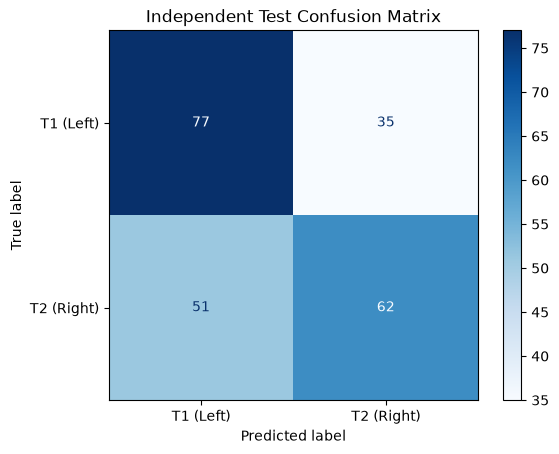

In [12]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display(pd.DataFrame(cm, index=["Actual T1", "Actual T2"], columns=["Predicted T1", "Predicted T2"]))

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["T1 (Left)", "T2 (Right)"]).plot(cmap="Blues", values_format="d")

plt.title("Independent Test Confusion Matrix")
plt.show()

**Conclusion:** CSP + LDA correctly classified 139 of 225 test epochs. T1 achieved higher recall (0.688) than T2 (0.549), with 51 T2 epochs incorrectly classified as T1. These results indicate a moderate prediction bias toward T1 despite above-chance overall performance.

## 5. Subject-Level Error Analysis

### 5.1 Individual Subject Performance

We evaluate balanced accuracy, Macro-F1, and prediction distributions separately for each independent test subject.

This analysis examines cross-subject variability without modifying the trained model.

In [13]:
subject_results = []

for subject in np.unique(groups_test):
    mask = groups_test == subject

    y_true = y_test[mask]
    y_subject_pred = y_pred[mask]

    subject_results.append({"Subject": subject,
                            "Epochs": len(y_true),
                            "BA": balanced_accuracy_score(y_true, y_subject_pred),
                            "Macro-F1": f1_score(y_true, y_subject_pred, average="macro"),
                            "Predicted T1": int(np.sum(y_subject_pred == 0)),
                            "Predicted T2": int(np.sum(y_subject_pred == 1))})

subject_df = pd.DataFrame(subject_results)
display(subject_df.round(3))

print("Mean subject BA:", round(subject_df["BA"].mean(), 3))
print("Std subject BA:", round(subject_df["BA"].std(), 3))
print("Min subject BA:", round(subject_df["BA"].min(), 3))
print("Max subject BA:", round(subject_df["BA"].max(), 3))

,Subject,Epochs,BA,Macro-F1,Predicted T1,Predicted T2
0,S021,45,0.711,0.711,23,22
1,S022,45,0.587,0.497,41,4
2,S023,45,0.594,0.564,10,35
3,S024,45,0.563,0.500,38,7
4,S025,45,0.641,0.636,16,29


Mean subject BA: 0.619
Std subject BA: 0.059
Min subject BA: 0.563
Max subject BA: 0.711


**Conclusion:** CSP + LDA achieved a mean subject-level BA of 0.619 (SD = 0.059), ranging from 0.563 to 0.711. Performance varied across unseen subjects, with noticeable class-prediction biases for S022, S023, and S024. These results highlight inter-subject variability despite consistent above-chance point estimates.

### 5.2 Subject-Level Confusion Matrices

We examine class-specific errors for each test subject to identify differences in prediction behavior.

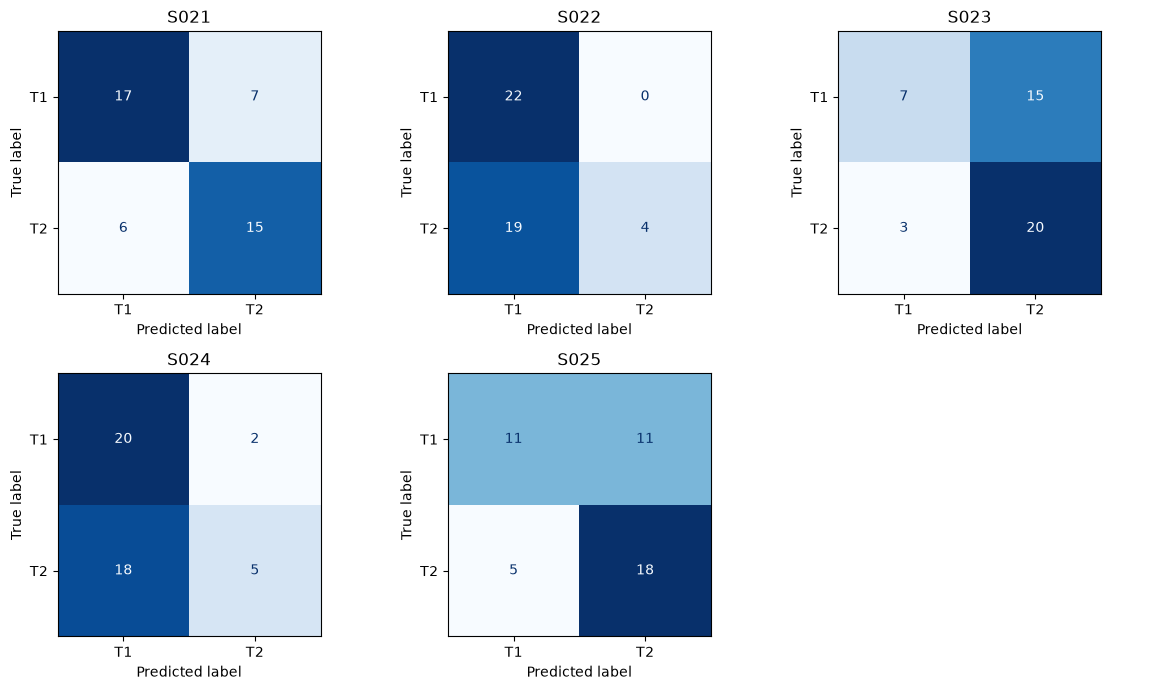

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for subject, ax in zip(np.unique(groups_test), axes.flat):
    mask = groups_test == subject
    cm_subject = confusion_matrix(y_test[mask], y_pred[mask], labels=[0, 1])

    ConfusionMatrixDisplay(cm_subject, display_labels=["T1", "T2"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")

    ax.set_title(subject)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

**Conclusion:** Subject-level confusion matrices revealed substantial differences in class-specific performance. S021 showed balanced recognition of both classes, while S022 and S024 exhibited strong T1 prediction bias and S023 favored T2. These findings highlight subject-dependent classification errors despite an overall test BA of 0.618.

## 6. Conclusions and Limitations

### Key Findings

- The selected CSP + LDA pipeline achieved an independent test balanced accuracy of **0.618** and Macro-F1 of **0.616** on 225 epochs from five unseen subjects.
- Test performance was close to the development LOSO BA of 0.624.
- Subject-level BA ranged from 0.563 to 0.711, with a mean of 0.619.
- Confusion matrices revealed substantial subject-dependent class prediction biases, particularly for S022, S023, and S024.

### Limitations

- Independent evaluation included only five subjects, limiting confidence in population-level generalization.
- EEG epochs from the same subject are correlated and should not be treated as independent observations when estimating uncertainty.
- Class-specific performance varied considerably across subjects.
- The model uses a fixed six-channel configuration without subject-specific calibration.

### Final Conclusion

CSP + LDA demonstrated above-chance point-estimate performance on previously unseen EEG subjects, with minimal difference between development LOSO and independent test balanced accuracy.

However, subject-specific prediction biases remain a major limitation. Future research should investigate methods that improve cross-subject robustness using separate development data, while preserving the independent test set for unbiased evaluation.